## 5.1 Persiapan Analytical Dataset

Analisis hubungan fitur dengan variabel target memerlukan dataset yang merepresentasikan setiap shipment dalam satu baris observasi.

Dataset utama `shipments` akan digabungkan dengan tabel master dan tabel transaksi operasional.

Tabel master yang digunakan:

- customers
- couriers
- hubs
- service_packages
- promotions

Tabel operasional yang digunakan:

- scan_events
- route_segments
- invoices

Tabel operasional dengan relasi one-to-many akan diagregasi berdasarkan shipment_id sebelum digabungkan dengan dataset utama.

Proses ini dilakukan untuk menghindari penggandaan observasi akibat penggabungan tabel yang memiliki jumlah record berbeda pada setiap shipment.

Fitur yang dihasilkan mencakup karakteristik shipment, profil entitas, frekuensi aktivitas operasional, karakteristik rute, serta informasi transaksi.

Hasil akhir merupakan analytical dataset dengan satu baris untuk setiap shipment pada dataset training.

In [10]:
from pathlib import Path
import os

import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

DATA_DIR = Path(os.getenv("DATA_DIR", "C:/Users/ASUS/.vscode/arkavidia/data/Task-1-Datavidia-11.0"))

OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "status_penanganan"
ID_COL = "shipment_id"

TARGET_CLASSES = [
    "normal",
    "konfirmasi_alamat",
    "tertunda_operasional",
    "gagal_antar_awal",
    "retur_pengirim",
    "rusak_perjalanan",
    "klaim_hilang"
]

SAMPLE_SIZE = 150000
MI_SAMPLE_SIZE = 50000

SEED = 42

def read_table(split, table, columns=None):

    path = DATA_DIR / split / f"{table}.csv"

    return pl.read_csv(
        path,
        columns=columns,
        infer_schema_length=20000
    )

print("Data directory:", DATA_DIR.resolve())
print("Target:", TARGET)
print("Total target classes:", len(TARGET_CLASSES))

Data directory: C:\Users\ASUS\.vscode\arkavidia\data\Task-1-Datavidia-11.0
Target: status_penanganan
Total target classes: 7


### 5.1.1 Integrasi Tabel dan Agregasi Transaksi

Tahap ini mengintegrasikan sembilan tabel menjadi satu analytical dataset.

Setiap tabel master digabungkan berdasarkan identifier masing-masing entitas.

Sementara itu, tabel operasional diringkas menggunakan agregasi statistik berdasarkan shipment_id.

Agregasi scan events mencakup jumlah aktivitas, distribusi jenis event, waktu antaraktivitas, kualitas scan, dan penggunaan pemindaian manual.

Agregasi route segments mencakup jumlah segmen, jarak, durasi, moda transportasi, dan jumlah hub yang dilalui.

Agregasi invoices mencakup jumlah transaksi, nominal pembayaran, diskon, denda, serta distribusi jenis invoice dan status pembayaran.

Informasi yang diperoleh digunakan untuk menganalisis kontribusi setiap sumber data terhadap status penanganan pengiriman.

In [11]:
SHIPMENT_COLUMNS = [
    "shipment_id",
    "status_penanganan",
    "customer_id",
    "courier_id",
    "hub_id",
    "package_id",
    "promo_id",
    "weight_kg",
    "volume_l",
    "declared_value",
    "distance_km",
    "ship_month",
    "ship_dow",
    "ship_hour",
    "is_cod",
    "is_promo",
    "channel",
    "pickup_type",
    "goods_category",
    "dest_region",
    "insurance_opt",
    "qty_items",
    "coupon_count",
    "gift_wrap",
    "fragility_flag",
    "order_to_ship_hours",
    "prioritas_pengiriman",
    "jumlah_catatan",
    "flag_alamat_baru",
    "berat_volumetrik",
    "kota_asal",
    "kota_tujuan",
    "skor_prioritas_kirim",
    "indeks_rute_sekunder",
    "faktor_muatan_internal",
    "varian_cuaca_rute",
    "indeks_waktu_proses",
    "skor_kualitas_cek"
]

shipments = read_table(
    "train",
    "shipments",
    SHIPMENT_COLUMNS
)

def load_lookup(table, key, features, prefix):

    df = read_table(
        "train",
        table,
        [key] + features
    )

    return df.rename({
        column: f"{prefix}{column}"
        for column in features
    })

customer_features = [
    "region",
    "segment",
    "tenure_months",
    "credit_score",
    "is_business",
    "preferred_payment",
    "loyalty_tier",
    "address_quality",
    "complaint_index",
    "is_verified",
    "kota_tipe",
    "metode_notifikasi",
    "tagihan_langganan"
]

courier_features = [
    "hub_id",
    "vehicle_type",
    "experience_years",
    "contract_type",
    "courier_score",
    "shift_code",
    "training_level",
    "jarak_domisili_hub_km",
    "kapasitas_muatan_kg",
    "sertifikasi_hazardous"
]

hub_features = [
    "region",
    "hub_type",
    "automation_level",
    "capacity_index",
    "density_index",
    "luas_gudang_m2",
    "jam_buka",
    "jam_tutup"
]

package_features = [
    "speed_class",
    "handling_class",
    "insurance_default",
    "cod_allowed",
    "cost_multiplier",
    "max_weight_kg",
    "fragile_score",
    "estimasi_hari",
    "biaya_dasar"
]

promotion_features = [
    "nama_promo",
    "tipe_promo",
    "diskon_persen",
    "bulan_mulai",
    "bulan_akhir"
]

customer_lookup = load_lookup(
    "customers",
    "customer_id",
    customer_features,
    "cust_"
)

courier_lookup = load_lookup(
    "couriers",
    "courier_id",
    courier_features,
    "cour_"
)

hub_lookup = load_lookup(
    "hubs",
    "hub_id",
    hub_features,
    "hub_"
)

package_lookup = load_lookup(
    "service_packages",
    "package_id",
    package_features,
    "pkg_"
)

promotion_lookup = load_lookup(
    "promotions",
    "promo_id",
    promotion_features,
    "promo_"
)

analysis_frame = (
    shipments
    .join(customer_lookup, on="customer_id", how="left")
    .join(courier_lookup, on="courier_id", how="left")
    .join(hub_lookup, on="hub_id", how="left")
    .join(package_lookup, on="package_id", how="left")
    .join(promotion_lookup, on="promo_id", how="left")
)

print("Shipment records:", shipments.height)
print("After master joins:", analysis_frame.height)
print("Unique shipment IDs:", analysis_frame["shipment_id"].n_unique())

Shipment records: 1243617
After master joins: 1243617
Unique shipment IDs: 1243617


In [12]:
EVENT_TYPES = [
    "pickup",
    "sortasi",
    "transit",
    "keluar_hub",
    "upaya_antar",
    "selesai"
]

scan_events = read_table(
    "train",
    "scan_events",
    [
        "shipment_id",
        "hub_id",
        "event_type",
        "gap_hours",
        "device_type",
        "scan_quality",
        "is_manual"
    ]
)

scan_expressions = [
    pl.len().alias("sc_count"),
    pl.col("event_type").n_unique().alias("sc_unique_event"),
    pl.col("hub_id").n_unique().alias("sc_unique_hubs"),
    pl.col("gap_hours").mean().alias("sc_gap_mean"),
    pl.col("gap_hours").median().alias("sc_gap_median"),
    pl.col("gap_hours").max().alias("sc_gap_max"),
    pl.col("gap_hours").sum().alias("sc_gap_sum"),
    pl.col("gap_hours").std().alias("sc_gap_std"),
    pl.col("scan_quality").mean().alias("sc_quality_mean"),
    pl.col("scan_quality").median().alias("sc_quality_median"),
    pl.col("scan_quality").min().alias("sc_quality_min"),
    pl.col("scan_quality").std().alias("sc_quality_std"),
    pl.col("is_manual").cast(pl.Float64, strict=False).sum().alias("sc_manual_count"),
    pl.col("is_manual").cast(pl.Float64, strict=False).mean().alias("sc_manual_rate"),
    pl.col("device_type").n_unique().alias("sc_unique_devices")
]

for event in EVENT_TYPES:

    scan_expressions.append(
        (pl.col("event_type") == event)
        .sum()
        .alias(f"sc_n_{event}")
    )

scan_agg = (
    scan_events
    .group_by("shipment_id")
    .agg(scan_expressions)
)

print("Scan aggregation shape:", scan_agg.shape)

Scan aggregation shape: (1243617, 22)


In [13]:
MODES = [
    "darat",
    "laut",
    "udara",
    "kereta"
]

route_segments = read_table(
    "train",
    "route_segments",
    [
        "shipment_id",
        "urutan",
        "moda",
        "jarak_segmen_km",
        "durasi_jam",
        "segmen_hub_id",
        "biaya_segmen"
    ]
)

route_sorted = route_segments.sort(
    ["shipment_id", "urutan"]
)

route_expressions = [
    pl.len().alias("rt_count"),
    pl.col("jarak_segmen_km").sum().alias("rt_distance_sum"),
    pl.col("jarak_segmen_km").mean().alias("rt_distance_mean"),
    pl.col("jarak_segmen_km").max().alias("rt_distance_max"),
    pl.col("durasi_jam").sum().alias("rt_duration_sum"),
    pl.col("durasi_jam").mean().alias("rt_duration_mean"),
    pl.col("durasi_jam").max().alias("rt_duration_max"),
    pl.col("durasi_jam").null_count().alias("rt_duration_missing"),
    pl.col("biaya_segmen").sum().alias("rt_cost_sum"),
    pl.col("biaya_segmen").mean().alias("rt_cost_mean"),
    pl.col("segmen_hub_id").n_unique().alias("rt_unique_hubs"),
    pl.col("moda").n_unique().alias("rt_unique_modes"),
    pl.col("moda").first().alias("rt_first_mode"),
    pl.col("moda").last().alias("rt_last_mode"),
    (
        pl.col("jarak_segmen_km")
        / pl.col("durasi_jam").clip(lower_bound=0.01)
    ).mean().alias("rt_speed_mean")
]

for mode in MODES:

    route_expressions.extend([
        (pl.col("moda") == mode)
        .sum()
        .alias(f"rt_n_{mode}"),

        pl.col("durasi_jam")
        .filter(pl.col("moda") == mode)
        .sum()
        .alias(f"rt_duration_{mode}"),

        pl.col("jarak_segmen_km")
        .filter(pl.col("moda") == mode)
        .sum()
        .alias(f"rt_distance_{mode}")
    ])

route_agg = (
    route_sorted
    .group_by("shipment_id")
    .agg(route_expressions)
)

print("Route aggregation shape:", route_agg.shape)

Route aggregation shape: (1243617, 28)


In [14]:
INVOICE_TYPES = [
    "pengiriman",
    "langganan",
    "klaim"
]

PAYMENT_STATUSES = [
    "lunas",
    "tertunda",
    "gagal"
]

invoices = read_table(
    "train",
    "invoices",
    [
        "shipment_id",
        "invoice_type",
        "amount",
        "discount",
        "tax",
        "payment_status",
        "days_to_pay",
        "is_penalty"
    ]
)

invoice_expressions = [
    pl.len().alias("iv_count"),
    pl.col("amount").sum().alias("iv_amount_sum"),
    pl.col("amount").mean().alias("iv_amount_mean"),
    pl.col("amount").max().alias("iv_amount_max"),
    pl.col("discount").sum().alias("iv_discount_sum"),
    pl.col("discount").null_count().alias("iv_discount_missing"),
    pl.col("tax").sum().alias("iv_tax_sum"),
    pl.col("days_to_pay").mean().alias("iv_days_mean"),
    pl.col("days_to_pay").max().alias("iv_days_max"),
    pl.col("is_penalty").cast(pl.Float64, strict=False).sum().alias("iv_penalty_count")
]

for invoice_type in INVOICE_TYPES:

    invoice_expressions.extend([
        (pl.col("invoice_type") == invoice_type)
        .sum()
        .alias(f"iv_n_{invoice_type}"),

        pl.col("amount")
        .filter(pl.col("invoice_type") == invoice_type)
        .sum()
        .alias(f"iv_amount_{invoice_type}")
    ])

for status in PAYMENT_STATUSES:

    invoice_expressions.append(
        (pl.col("payment_status") == status)
        .sum()
        .alias(f"iv_n_{status}")
    )

invoice_agg = (
    invoices
    .group_by("shipment_id")
    .agg(invoice_expressions)
)

print("Invoice aggregation shape:", invoice_agg.shape)

Invoice aggregation shape: (1243617, 20)


In [15]:
analysis_frame = (
    analysis_frame
    .join(scan_agg, on="shipment_id", how="left")
    .join(route_agg, on="shipment_id", how="left")
    .join(invoice_agg, on="shipment_id", how="left")
)

analysis_frame = analysis_frame.with_columns([
    pl.col("promo_nama_promo").fill_null("TANPA_PROMO"),
    pl.col("promo_tipe_promo").fill_null("TANPA_PROMO")
])

analysis_frame = analysis_frame.with_columns([
    (
        pl.col("declared_value").clip(lower_bound=0) + 1
    ).log().alias("log_declared_value"),

    (
        pl.col("declared_value")
        / pl.col("weight_kg").clip(lower_bound=0.01)
    ).alias("r_value_per_kg"),

    (
        pl.col("berat_volumetrik")
        / pl.col("weight_kg").clip(lower_bound=0.01)
    ).alias("r_volumetric_weight"),

    (
        pl.col("hub_density_index")
        / pl.col("hub_capacity_index").clip(lower_bound=0.01)
    ).alias("r_hub_load"),

    (
        pl.col("rt_duration_sum")
        / (pl.col("pkg_estimasi_hari") * 24).clip(lower_bound=0.01)
    ).alias("r_duration_estimation"),

    (
        pl.col("rt_distance_sum")
        - pl.col("distance_km")
    ).alias("x_route_distance_difference"),

    (
        pl.col("fragility_flag")
        * pl.col("pkg_fragile_score")
    ).alias("x_fragility"),

    (
        pl.col("flag_alamat_baru")
        * pl.col("jumlah_catatan")
    ).alias("x_address_risk")
])

assert analysis_frame.height == shipments.height
assert analysis_frame["shipment_id"].n_unique() == shipments.height

print("Final analytical dataset:", analysis_frame.shape)
print("Unique shipment IDs:", analysis_frame["shipment_id"].n_unique())

display(
    analysis_frame.head(5)
)

Final analytical dataset: (1243617, 158)
Unique shipment IDs: 1243617


shipment_id,status_penanganan,customer_id,courier_id,hub_id,package_id,promo_id,weight_kg,volume_l,declared_value,distance_km,ship_month,ship_dow,ship_hour,is_cod,is_promo,channel,pickup_type,goods_category,dest_region,insurance_opt,qty_items,coupon_count,gift_wrap,fragility_flag,order_to_ship_hours,prioritas_pengiriman,jumlah_catatan,flag_alamat_baru,berat_volumetrik,kota_asal,kota_tujuan,skor_prioritas_kirim,indeks_rute_sekunder,faktor_muatan_internal,varian_cuaca_rute,indeks_waktu_proses,…,rt_distance_darat,rt_n_laut,rt_duration_laut,rt_distance_laut,rt_n_udara,rt_duration_udara,rt_distance_udara,rt_n_kereta,rt_duration_kereta,rt_distance_kereta,iv_count,iv_amount_sum,iv_amount_mean,iv_amount_max,iv_discount_sum,iv_discount_missing,iv_tax_sum,iv_days_mean,iv_days_max,iv_penalty_count,iv_n_pengiriman,iv_amount_pengiriman,iv_n_langganan,iv_amount_langganan,iv_n_klaim,iv_amount_klaim,iv_n_lunas,iv_n_tertunda,iv_n_gagal,log_declared_value,r_value_per_kg,r_volumetric_weight,r_hub_load,r_duration_estimation,x_route_distance_difference,x_fragility,x_address_risk
str,str,str,str,str,str,str,f64,f64,i64,f64,i64,i64,i64,i64,i64,str,str,str,str,i64,i64,i64,i64,i64,f64,i64,i64,i64,f64,str,str,f64,f64,f64,f64,f64,…,f64,u32,f64,f64,u32,f64,f64,u32,f64,f64,u32,i64,f64,i64,f64,u32,i64,f64,i64,f64,u32,i64,u32,i64,u32,i64,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64
"""SHP-AHSVFB3R""","""normal""","""CUS-5VB7S4ZY""","""CRV-DZEF3GM9""","""HUB-MSVB47XA""","""PKG-NZ3YX33Z""","""TANPA_PROMO""",3.75,7.9,16000,1277.6,3,6,16,0,0,"""aplikasi""","""agen""","""kesehatan""","""sumatera""",1,2,1,0,0,1.4,2,0,0,6.69,"""banyuwangi""","""jayapura""",39.5,43.72,37.79,47.06,57.0,…,1277.6,0,0.0,0.0,0,0.0,0.0,0,0.0,0.0,1,7000,7000.0,7000,1200.0,0,800,2.0,2,0.0,1,7000,0,0,0,0,0,1,0,9.680406,4266.666667,1.784,0.618613,0.453333,0.0,0.0,0
"""SHP-FUWWVBCQ""","""retur_pengirim""","""CUS-79DW3KY8""","""CRV-S8LG8JQP""","""HUB-B83PJTMD""","""PKG-GTVK7E6E""","""PRM-F82RASMM""",1.46,3.4,23000,515.9,7,5,16,0,1,"""agen""","""dropoff""","""makanan""","""sulawesi""",1,1,0,0,0,6.6,2,0,0,3.56,"""manado""","""palu""",48.35,63.08,44.36,63.36,35.57,…,515.9,0,0.0,0.0,0,0.0,0.0,0,0.0,0.0,1,10000,10000.0,10000,0.0,1,1100,6.0,6,0.0,0,0,1,10000,0,0,1,0,0,10.043293,15753.424658,2.438356,0.483945,0.2625,0.0,0.0,0
"""SHP-9EBN7MB9""","""normal""","""CUS-642HAPWJ""","""CRV-EQ3SX46G""","""HUB-AGDQJQVF""","""PKG-QPNPLAVN""","""TANPA_PROMO""",3.3,8.0,119000,653.1,6,1,12,0,0,"""agen""","""agen""","""kesehatan""","""sulawesi""",1,3,0,0,0,8.4,1,1,0,7.18,"""bandung""","""solo""",59.01,55.77,55.04,54.16,48.49,…,0.0,1,34.2,653.1,0,0.0,0.0,0,0.0,0.0,2,23000,11500.0,12000,2000.0,0,2500,5.5,8,0.0,1,11000,0,0,1,12000,2,0,0,11.686887,36060.606061,2.175758,1.755481,0.285,0.0,0.0,0
"""SHP-5LK9F3MX""","""retur_pengirim""","""CUS-QDZSXZWD""","""CRV-XYHRH2DD""","""HUB-22X96KLN""","""PKG-2Y2RN6AW""","""TANPA_PROMO""",4.77,7.5,98000,434.5,2,5,17,0,0,"""agen""","""dropoff""","""kesehatan""","""jawa_barat""",0,1,0,0,1,6.6,2,1,0,12.34,"""surabaya""","""pekanbaru""",47.49,49.37,61.23,42.1,50.49,…,293.9,0,0.0,0.0,1,2.89,140.6,0,0.0,0.0,1,7000,7000.0,7000,0.0,1,800,1.0,1,0.0,0,0,1,7000,0,0,1,0,0,11.492733,20545.073375,2.587002,0.657849,0.472083,0.0,0.14,0
"""SHP-6XV4H3CP""","""konfirmasi_alamat""","""CUS-QADQDZQ3""","""CRV-LQWU6RFS""","""HUB-YZUUKVTW""","""PKG-R3P3KWCQ""","""PRM-EAXBNEFE""",3.24,6.4,86000,997.4,8,1,10,0,1,"""aplikasi""","""jemput""","""fashion""","""jawa_timur""",1,1,1,0,1,3.4,1,0,0,3.98,"""kudus""","""purwokerto""",47.34,56.25,54.06,52.92,44.46,…,997.4,0,0.0,0.0,0,0.0,0.0,0,0.0,0.0,1,9000,9000.0,9000,500.0,0,1000,0.0,0,0.0,1,9000,0,0,0,0,1,0,0,11.362114,26543.209877,1.228395,0.622333,0.765,0.0,0.54,0


### 5.2 Analisis Asosiasi Fitur Numerik Menggunakan Eta-squared

Eta-squared digunakan untuk mengukur proporsi variasi suatu fitur numerik yang dapat dijelaskan oleh perbedaan kelompok target.

Dalam analisis ini, setiap fitur numerik dibandingkan berdasarkan tujuh kelas status_penanganan.

Nilai eta-squared berada pada rentang 0 sampai 1.

Interpretasi umum:

- Mendekati 0 menunjukkan asosiasi yang lemah.
- Semakin besar nilainya menunjukkan perbedaan karakteristik numerik antarkelas yang semakin kuat.

Analisis dilakukan terhadap fitur dari tabel shipment, customer, courier, hub, package, scan events, route segments, dan invoices.

Hasil pengukuran akan digunakan untuk menyusun ranking fitur numerik berdasarkan kekuatan asosiasinya dengan target.

Eta-squared digunakan sebagai ukuran effect size, bukan sebagai bukti hubungan sebab-akibat.

In [16]:
IDENTIFIER_COLUMNS = [
    "shipment_id",
    "customer_id",
    "courier_id",
    "event_id",
    "segment_id",
    "invoice_id"
]

NUMERIC_TYPE_NAMES = {
    "Int8",
    "Int16",
    "Int32",
    "Int64",
    "UInt8",
    "UInt16",
    "UInt32",
    "UInt64",
    "Float32",
    "Float64",
    "Boolean"
}

numeric_features = [
    column
    for column, dtype in analysis_frame.schema.items()
    if (
        str(dtype) in NUMERIC_TYPE_NAMES
        and column not in IDENTIFIER_COLUMNS
        and column != TARGET
    )
]

print("Total numerical features:", len(numeric_features))
print(numeric_features)

Total numerical features: 127
['weight_kg', 'volume_l', 'declared_value', 'distance_km', 'ship_month', 'ship_dow', 'ship_hour', 'is_cod', 'is_promo', 'insurance_opt', 'qty_items', 'coupon_count', 'gift_wrap', 'fragility_flag', 'order_to_ship_hours', 'prioritas_pengiriman', 'jumlah_catatan', 'flag_alamat_baru', 'berat_volumetrik', 'skor_prioritas_kirim', 'indeks_rute_sekunder', 'faktor_muatan_internal', 'varian_cuaca_rute', 'indeks_waktu_proses', 'skor_kualitas_cek', 'cust_tenure_months', 'cust_credit_score', 'cust_is_business', 'cust_address_quality', 'cust_complaint_index', 'cust_is_verified', 'cust_tagihan_langganan', 'cour_experience_years', 'cour_courier_score', 'cour_training_level', 'cour_jarak_domisili_hub_km', 'cour_kapasitas_muatan_kg', 'cour_sertifikasi_hazardous', 'hub_automation_level', 'hub_capacity_index', 'hub_density_index', 'hub_luas_gudang_m2', 'hub_jam_buka', 'hub_jam_tutup', 'pkg_insurance_default', 'pkg_cod_allowed', 'pkg_cost_multiplier', 'pkg_max_weight_kg', 'pkg

In [17]:
def calculate_eta_squared(frame, target, features):

    global_expressions = []
    group_expressions = []

    for feature in features:

        x = (
            pl.col(feature)
            .cast(pl.Float64, strict=False)
            .fill_nan(None)
        )

        global_expressions.extend([
            x.count().alias(f"{feature}__n"),
            x.sum().alias(f"{feature}__sum"),
            (x * x).sum().alias(f"{feature}__sum_sq")
        ])

        group_expressions.extend([
            x.count().alias(f"{feature}__n"),
            x.mean().alias(f"{feature}__mean")
        ])

    global_stats = frame.select(
        global_expressions
    ).row(0, named=True)

    group_stats = frame.group_by(target).agg(
        group_expressions
    )

    results = []

    for feature in features:

        n = global_stats[f"{feature}__n"]

        total_sum = global_stats[f"{feature}__sum"]
        total_sum_sq = global_stats[f"{feature}__sum_sq"]

        if n is None or n <= 1:
            continue

        grand_mean = total_sum / n

        ss_total = (
            total_sum_sq
            - (total_sum ** 2 / n)
        )

        between = 0.0

        for row in group_stats.iter_rows(named=True):

            group_n = row[f"{feature}__n"]
            group_mean = row[f"{feature}__mean"]

            if group_n and group_mean is not None:

                between += (
                    group_n
                    * (group_mean - grand_mean) ** 2
                )

        if ss_total is None or ss_total <= 0:
            eta_squared = np.nan
        else:
            eta_squared = max(
                0.0,
                min(1.0, between / ss_total)
            )

        results.append({
            "Feature": feature,
            "Eta Squared": eta_squared,
            "Grand Mean": grand_mean,
            "Valid Observations": n
        })

    return pd.DataFrame(results)


eta_squared_df = (
    calculate_eta_squared(
        analysis_frame,
        TARGET,
        numeric_features
    )
    .sort_values("Eta Squared", ascending=False)
    .reset_index(drop=True)
)

print("Total features evaluated:", len(eta_squared_df))
display(eta_squared_df.head(20))

Total features evaluated: 127


,Feature,Eta Squared,Grand Mean,Valid Observations
0,cust_address_quality,0.307411,3.175691,1243617
1,cust_complaint_index,0.296791,0.241407,1243617
2,hub_density_index,0.128459,0.498544,1243617
3,cour_courier_score,0.119699,3.575678,1230239
4,hub_capacity_index,0.110993,0.538940,1243617
5,sc_gap_mean,0.099137,8.412638,1243617
6,sc_quality_mean,0.094962,3.636019,1243617
7,sc_gap_median,0.079214,7.048513,1243617
8,sc_quality_median,0.075677,3.686720,1243617
9,sc_gap_sum,0.066563,46.266478,1243617


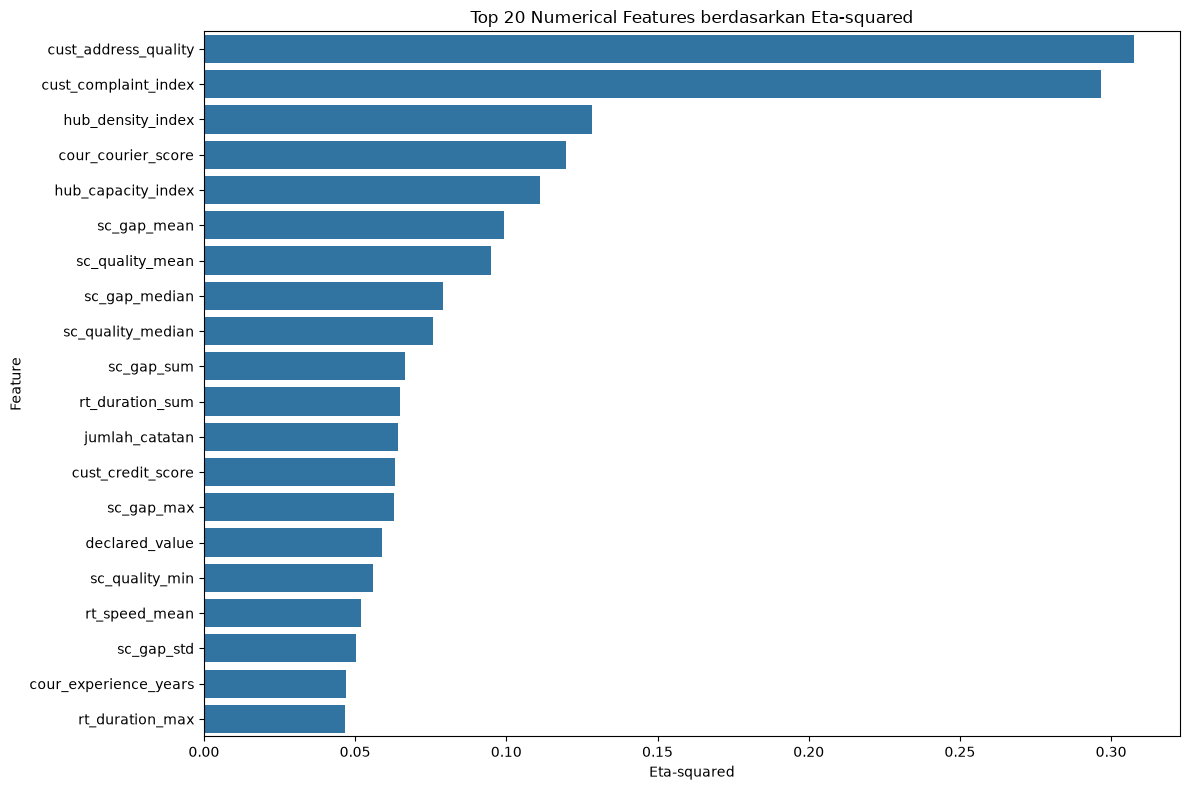

In [18]:
top_eta = eta_squared_df.head(20).copy()

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_eta,
    x="Eta Squared",
    y="Feature"
)

plt.title("Top 20 Numerical Features berdasarkan Eta-squared")
plt.xlabel("Eta-squared")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 5.3 Analisis Distribusi Numerik Berdasarkan Kelas

Eta-squared memberikan ukuran asosiasi secara keseluruhan, tetapi belum menjelaskan karakteristik setiap kelas secara spesifik.

Oleh karena itu, dilakukan analisis distribusi numerik berdasarkan masing-masing status penanganan.

Statistik yang digunakan:

- Jumlah observasi valid.
- Mean.
- Median.
- Standard deviation.
- Kuartil pertama.
- Kuartil ketiga.
- Persentil ke-90.

Analisis ini bertujuan mengidentifikasi perbedaan pola distribusi fitur numerik antarkelas serta menemukan fitur yang memiliki karakteristik khusus pada kelas minoritas.

In [19]:
profile_features = (
    eta_squared_df
    .head(15)["Feature"]
    .tolist()
)

profile_expressions = []

for feature in profile_features:

    x = (
        pl.col(feature)
        .cast(pl.Float64, strict=False)
        .fill_nan(None)
    )

    profile_expressions.extend([
        x.count().alias(f"{feature}__count"),
        x.mean().alias(f"{feature}__mean"),
        x.median().alias(f"{feature}__median"),
        x.std().alias(f"{feature}__std"),
        x.quantile(0.25).alias(f"{feature}__q25"),
        x.quantile(0.75).alias(f"{feature}__q75"),
        x.quantile(0.90).alias(f"{feature}__q90")
    ])

class_distribution_stats = (
    analysis_frame
    .group_by(TARGET)
    .agg(profile_expressions)
    .sort(TARGET)
)

display(class_distribution_stats)

status_penanganan,cust_address_quality__count,cust_address_quality__mean,cust_address_quality__median,cust_address_quality__std,cust_address_quality__q25,cust_address_quality__q75,cust_address_quality__q90,cust_complaint_index__count,cust_complaint_index__mean,cust_complaint_index__median,cust_complaint_index__std,cust_complaint_index__q25,cust_complaint_index__q75,cust_complaint_index__q90,hub_density_index__count,hub_density_index__mean,hub_density_index__median,hub_density_index__std,hub_density_index__q25,hub_density_index__q75,hub_density_index__q90,cour_courier_score__count,cour_courier_score__mean,cour_courier_score__median,cour_courier_score__std,cour_courier_score__q25,cour_courier_score__q75,cour_courier_score__q90,hub_capacity_index__count,hub_capacity_index__mean,hub_capacity_index__median,hub_capacity_index__std,hub_capacity_index__q25,hub_capacity_index__q75,hub_capacity_index__q90,sc_gap_mean__count,…,sc_gap_sum__q75,sc_gap_sum__q90,rt_duration_sum__count,rt_duration_sum__mean,rt_duration_sum__median,rt_duration_sum__std,rt_duration_sum__q25,rt_duration_sum__q75,rt_duration_sum__q90,jumlah_catatan__count,jumlah_catatan__mean,jumlah_catatan__median,jumlah_catatan__std,jumlah_catatan__q25,jumlah_catatan__q75,jumlah_catatan__q90,cust_credit_score__count,cust_credit_score__mean,cust_credit_score__median,cust_credit_score__std,cust_credit_score__q25,cust_credit_score__q75,cust_credit_score__q90,sc_gap_max__count,sc_gap_max__mean,sc_gap_max__median,sc_gap_max__std,sc_gap_max__q25,sc_gap_max__q75,sc_gap_max__q90,declared_value__count,declared_value__mean,declared_value__median,declared_value__std,declared_value__q25,declared_value__q75,declared_value__q90
str,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,…,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64
"""gagal_antar_awal""",124341,2.98488,3.0,0.934047,2.0,4.0,4.0,124341,0.242939,0.236305,0.163311,0.116242,0.354378,0.461864,124341,0.478879,0.479998,0.186934,0.354848,0.599281,0.718136,122982,2.891561,3.0,0.859258,2.0,3.0,4.0,124341,0.524653,0.527098,0.176525,0.415635,0.642047,0.747849,124341,…,57.26,77.11,124341,23.043871,20.69,14.032605,12.78,30.55,41.46,124341,0.491511,0.0,0.636994,0.0,1.0,1.0,121880,548.036417,547.751529,61.930232,506.160031,590.088628,627.724953,124341,17.226966,15.1,9.902219,10.44,21.49,29.61,124341,131354.854794,75000.0,183386.009292,36000.0,155000.0,294000.0
"""klaim_hilang""",37656,3.581421,4.0,1.019819,3.0,4.0,5.0,37656,0.187896,0.167861,0.161494,0.037486,0.297841,0.412587,37656,0.48042,0.489106,0.176456,0.363434,0.58938,0.698673,37203,3.531758,4.0,0.892436,3.0,4.0,5.0,37656,0.533106,0.538557,0.173205,0.437466,0.647251,0.750902,37656,…,57.38,77.67,37656,23.462343,21.12,14.20502,13.14,31.17,42.1,37656,0.381347,0.0,0.599824,0.0,1.0,1.0,36870,548.508108,548.186925,61.595582,506.612516,590.230161,627.91154,37656,17.261899,15.05,10.030918,10.44,21.49,29.86,37656,411054.971319,257000.0,512912.25014,128000.0,499000.0,895000.0
"""konfirmasi_alamat""",272911,2.026331,2.0,0.868957,1.0,3.0,3.0,272911,0.412604,0.408819,0.185909,0.284711,0.536124,0.65448,272911,0.489153,0.487565,0.192978,0.357262,0.614008,0.738938,269995,3.643056,4.0,0.873172,3.0,4.0,5.0,272911,0.531864,0.531213,0.178557,0.418795,0.650496,0.753903,272911,…,58.44,78.95,272911,24.435126,22.0,14.79676,13.59,32.49,43.84,272911,0.768536,1.0,0.650263,0.0,1.0,1.0,267500,553.353922,553.303398,62.982849,510.805019,595.870456,634.274893,272911,17.560753,15.31,10.259744,10.53,22.0,30.34,272911,134808.948705,75000.0,194584.813594,36000.0,156000.0,302000.0
"""normal""",473531,3.696465,4.0,1.001191,3.0,4.0,5.0,473531,0.15286,0.120473,0.152388,0.0,0.255566,0.372742,473531,0.449897,0.451209,0.190503,0.320939,0.571394,0.696139,468502,3.847638,4.0,0.858622,3.0,4.0,5.0,473531,0.49498,0.487238,0.176286,0.378204,0.6

In [20]:
distribution_records = []

for row in class_distribution_stats.iter_rows(named=True):

    target_class = row[TARGET]

    for feature in profile_features:

        distribution_records.append({
            "Class": target_class,
            "Feature": feature,
            "Count": row[f"{feature}__count"],
            "Mean": row[f"{feature}__mean"],
            "Median": row[f"{feature}__median"],
            "Std": row[f"{feature}__std"],
            "Q25": row[f"{feature}__q25"],
            "Q75": row[f"{feature}__q75"],
            "Q90": row[f"{feature}__q90"]
        })

numeric_class_distribution_df = pd.DataFrame(
    distribution_records
)

display(numeric_class_distribution_df)

,Class,Feature,Count,Mean,Median,Std,Q25,Q75,Q90
0,gagal_antar_awal,cust_address_quality,124341,2.984880,3.000000,0.934047,2.000000,4.000000,4.000000
1,gagal_antar_awal,cust_complaint_index,124341,0.242939,0.236305,0.163311,0.116242,0.354378,0.461864
2,gagal_antar_awal,hub_density_index,124341,0.478879,0.479998,0.186934,0.354848,0.599281,0.718136
3,gagal_antar_awal,cour_courier_score,122982,2.891561,3.000000,0.859258,2.000000,3.000000,4.000000
4,gagal_antar_awal,hub_capacity_index,124341,0.524653,0.527098,0.176525,0.415635,0.642047,0.747849
...,...,...,...,...,...,...,...,...,...
100,tertunda_operasional,rt_duration_sum,185496,32.899215,29.820000,19.380657,18.840000,43.390000,58.110000
101,tertunda_operasional,jumlah_catatan,185496,0.407459,0.000000,0.608694,0.000000,1.000000,1.000000
102,tertunda_operasional,cust_credit_score,181799,540.663738,541.060574,66.728675,495.333007,586.241799,626.235252
103,tertunda_operasional,sc_gap_max,185496,24.270131,21.290000,13.789982,14.810000,30.280000,41.620000


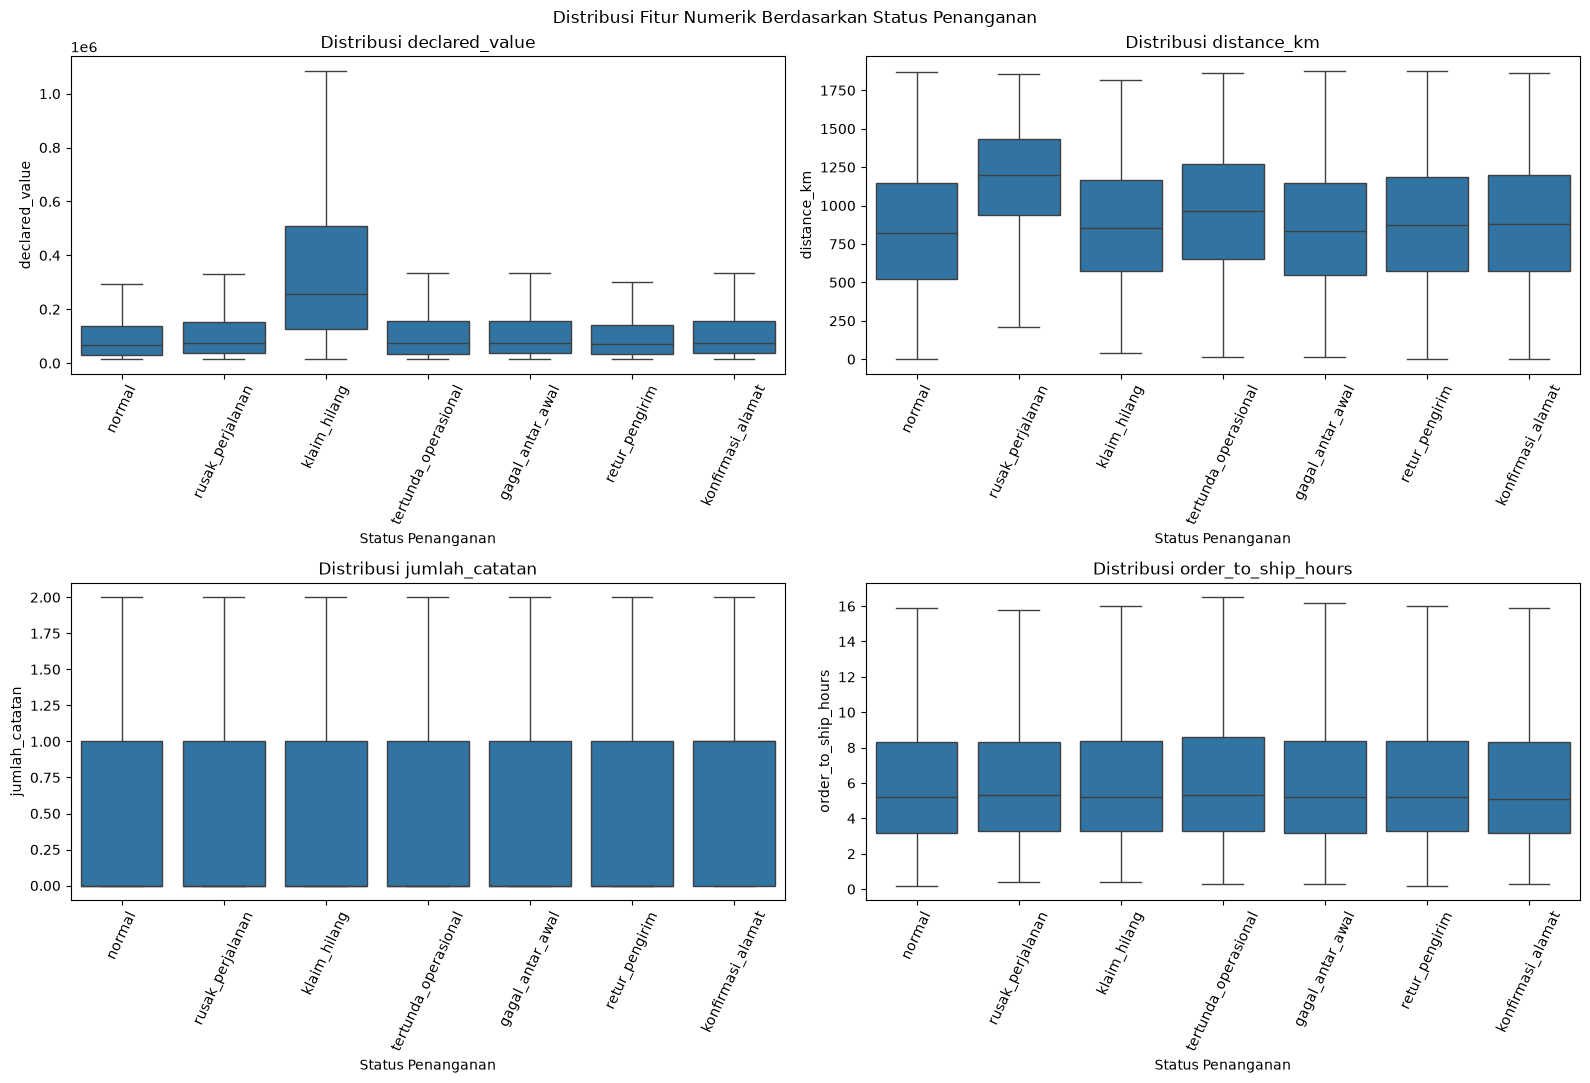

In [21]:
plot_features = [
    feature
    for feature in [
        "declared_value",
        "distance_km",
        "jumlah_catatan",
        "order_to_ship_hours"
    ]
    if feature in analysis_frame.columns
]

plot_sample = (
    analysis_frame
    .select([TARGET] + plot_features)
    .sample(
        n=min(100000, analysis_frame.height),
        seed=SEED
    )
    .to_pandas()
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

for ax, feature in zip(axes.flatten(), plot_features):

    sns.boxplot(
        data=plot_sample,
        x=TARGET,
        y=feature,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"Distribusi {feature}")
    ax.set_xlabel("Status Penanganan")
    ax.set_ylabel(feature)
    ax.tick_params(
        axis="x",
        rotation=65
    )

for ax in axes.flatten()[len(plot_features):]:
    ax.set_visible(False)

plt.suptitle(
    "Distribusi Fitur Numerik Berdasarkan Status Penanganan"
)

plt.tight_layout()
plt.show()

### 5.4 Analisis Effect Size per Kelas

Selain mengukur hubungan fitur dengan seluruh kelas menggunakan eta-squared, analisis dilanjutkan dengan menghitung Standardized Mean Difference.

Standardized Mean Difference digunakan untuk mengukur perbedaan rata-rata suatu fitur antara satu kelas dengan seluruh kelas lainnya.

Analisis dilakukan secara one-versus-rest untuk setiap kategori target.

Nilai yang dihasilkan menunjukkan arah dan besarnya perbedaan karakteristik fitur pada suatu kelas terhadap kelompok kelas lainnya.

Nilai positif menunjukkan rata-rata fitur pada kelas yang dianalisis lebih tinggi dibandingkan kelas lainnya.

Nilai negatif menunjukkan rata-rata yang lebih rendah.

Analisis ini digunakan untuk menemukan fitur yang mempunyai karakteristik khusus pada kelas minoritas.

Karena beberapa fitur memiliki distribusi yang tidak simetris, hasil Standardized Mean Difference akan digunakan sebagai ukuran komparatif dan tidak berdiri sendiri sebagai kesimpulan statistik.

In [22]:
global_smd_expressions = []
group_smd_expressions = []

for feature in numeric_features:

    x = (
        pl.col(feature)
        .cast(pl.Float64, strict=False)
        .fill_nan(None)
    )

    global_smd_expressions.extend([
        x.count().alias(f"{feature}__n"),
        x.sum().alias(f"{feature}__sum"),
        (x * x).sum().alias(f"{feature}__sum_sq")
    ])

    group_smd_expressions.extend([
        x.count().alias(f"{feature}__n"),
        x.sum().alias(f"{feature}__sum"),
        (x * x).sum().alias(f"{feature}__sum_sq")
    ])

global_smd_stats = analysis_frame.select(
    global_smd_expressions
).row(0, named=True)

class_smd_stats = analysis_frame.group_by(
    TARGET
).agg(
    group_smd_expressions
)

smd_records = []

for row in class_smd_stats.iter_rows(named=True):

    target_class = row[TARGET]

    for feature in numeric_features:

        n_class = row[f"{feature}__n"]
        sum_class = row[f"{feature}__sum"]
        sum_sq_class = row[f"{feature}__sum_sq"]

        n_total = global_smd_stats[f"{feature}__n"]
        sum_total = global_smd_stats[f"{feature}__sum"]
        sum_sq_total = global_smd_stats[f"{feature}__sum_sq"]

        n_rest = n_total - n_class

        if n_class < 2 or n_rest < 2:
            continue

        sum_rest = sum_total - sum_class
        sum_sq_rest = sum_sq_total - sum_sq_class

        mean_class = sum_class / n_class
        mean_rest = sum_rest / n_rest

        var_class = (
            sum_sq_class - sum_class ** 2 / n_class
        ) / (n_class - 1)

        var_rest = (
            sum_sq_rest - sum_rest ** 2 / n_rest
        ) / (n_rest - 1)

        pooled_variance = (
            (n_class - 1) * max(var_class, 0)
            + (n_rest - 1) * max(var_rest, 0)
        ) / (n_class + n_rest - 2)

        pooled_std = np.sqrt(
            max(pooled_variance, 0)
        )

        smd = (
            (mean_class - mean_rest) / pooled_std
            if pooled_std > 0
            else np.nan
        )

        smd_records.append({
            "Class": target_class,
            "Feature": feature,
            "Class Mean": mean_class,
            "Rest Mean": mean_rest,
            "SMD": smd,
            "Absolute SMD": abs(smd) if np.isfinite(smd) else np.nan
        })

classwise_smd_df = pd.DataFrame(smd_records)

classwise_smd_df = classwise_smd_df.sort_values(
    "Absolute SMD",
    ascending=False
).reset_index(drop=True)

display(classwise_smd_df.head(30))

,Class,Feature,Class Mean,Rest Mean,SMD,Absolute SMD
0,konfirmasi_alamat,cust_address_quality,2.026331e+00,3.498830e+00,-1.469278,1.469278
1,klaim_hilang,declared_value,4.110550e+05,1.257306e+05,1.438720,1.438720
2,konfirmasi_alamat,cust_complaint_index,4.126045e-01,1.932759e-01,1.246359,1.246359
3,klaim_hilang,log_declared_value,1.241468e+01,1.120112e+01,1.203699,1.203699
4,klaim_hilang,iv_amount_mean,1.461312e+04,1.032025e+04,1.123136,1.123136
5,klaim_hilang,iv_amount_max,1.595993e+04,1.086601e+04,1.098907,1.098907
6,tertunda_operasional,hub_density_index,6.670813e-01,4.689977e-01,1.045958,1.045958
7,rusak_perjalanan,sc_quality_mean,3.091867e+00,3.664543e+00,-1.041847,1.041847
8,klaim_hilang,iv_amount_sum,2.008716e+04,1.254489e+04,0.987252,0.987252
9,klaim_hilang,iv_tax_sum,2.207826e+03,1.385898e+03,0.986763,0.986763


In [23]:
top_classwise_smd = (
    classwise_smd_df
    .sort_values(
        ["Class", "Absolute SMD"],
        ascending=[True, False]
    )
    .groupby("Class")
    .head(10)
)

display(top_classwise_smd)

,Class,Feature,Class Mean,Rest Mean,SMD,Absolute SMD
16,gagal_antar_awal,cour_courier_score,2.891561,3.651663,-0.840646,0.840646
39,gagal_antar_awal,cour_experience_years,3.369436,4.056613,-0.513651,0.513651
44,gagal_antar_awal,sc_quality_mean,3.398056,3.662454,-0.473826,0.473826
51,gagal_antar_awal,sc_quality_median,3.447511,3.713294,-0.420369,0.420369
62,gagal_antar_awal,sc_quality_min,2.410589,2.726763,-0.372331,0.372331
...,...,...,...,...,...,...
25,tertunda_operasional,sc_gap_max,24.270131,16.839080,0.709099,0.709099
27,tertunda_operasional,sc_gap_std,8.475534,5.874646,0.629445,0.629445
28,tertunda_operasional,rt_speed_mean,33.861140,43.206698,-0.627338,0.627338
29,tertunda_operasional,rt_duration_sum,32.899215,23.444371,0.622127,0.622127


### 5.5 Analisis Asosiasi Fitur Kategorikal Menggunakan Cramér's V

Cramér's V digunakan untuk mengukur kekuatan hubungan antara dua variabel kategorikal.

Pada analisis ini, fitur kategorikal dibandingkan dengan variabel target status_penanganan.

Nilai Cramér's V berada pada rentang 0 sampai 1.

Nilai yang semakin mendekati 1 menunjukkan hubungan kategorikal yang semakin kuat, sedangkan nilai mendekati 0 menunjukkan hubungan yang lebih lemah.

Analisis mencakup fitur seperti:

- hub_id
- package_id
- promo_id
- goods_category
- channel
- pickup_type
- dest_region
- kota_asal
- kota_tujuan
- customer segment
- courier vehicle type
- service package category

Pengukuran menggunakan bias-corrected Cramér's V untuk mengurangi bias akibat ukuran sampel dan banyaknya kategori.

Fitur dengan cardinality sangat tinggi tidak dimasukkan dalam pengujian awal untuk menghindari tabel kontingensi yang terlalu besar dan interpretasi asosiasi yang tidak stabil.

In [24]:
CATEGORICAL_CANDIDATES = [
    "hub_id",
    "package_id",
    "promo_id",
    "channel",
    "pickup_type",
    "goods_category",
    "dest_region",
    "kota_asal",
    "kota_tujuan",
    "cust_region",
    "cust_segment",
    "cust_preferred_payment",
    "cust_loyalty_tier",
    "cust_kota_tipe",
    "cust_metode_notifikasi",
    "cour_vehicle_type",
    "cour_contract_type",
    "cour_shift_code",
    "cour_training_level",
    "hub_region",
    "hub_hub_type",
    "pkg_speed_class",
    "pkg_handling_class",
    "promo_nama_promo",
    "promo_tipe_promo",
    "rt_first_mode",
    "rt_last_mode",
    "is_cod",
    "is_promo",
    "insurance_opt",
    "gift_wrap",
    "fragility_flag",
    "cust_is_business",
    "cust_is_verified"
]

categorical_candidates = [
    feature
    for feature in CATEGORICAL_CANDIDATES
    if feature in analysis_frame.columns
]

categorical_cardinality = analysis_frame.select([
    pl.col(feature).n_unique().alias(feature)
    for feature in categorical_candidates
]).row(0, named=True)

MAX_CRAMERS_CARDINALITY = 1000

categorical_features = [
    feature
    for feature in categorical_candidates
    if categorical_cardinality[feature] <= MAX_CRAMERS_CARDINALITY
]

cardinality_report = pd.DataFrame([
    {
        "Feature": feature,
        "Unique Values": categorical_cardinality[feature],
        "Included": feature in categorical_features
    }
    for feature in categorical_candidates
]).sort_values(
    "Unique Values",
    ascending=False
)

display(cardinality_report)

,Feature,Unique Values,Included
0,hub_id,654,True
1,package_id,62,True
8,kota_tujuan,44,True
7,kota_asal,44,True
2,promo_id,35,True
23,promo_nama_promo,20,True
9,cust_region,7,True
6,dest_region,7,True
19,hub_region,7,True
5,goods_category,6,True


In [25]:
cramer_features = categorical_features.copy()

cramer_columns = [TARGET] + cramer_features

cramer_sample = (
    analysis_frame
    .select(cramer_columns)
    .sample(
        n=min(SAMPLE_SIZE, analysis_frame.height),
        seed=SEED
    )
    .to_pandas()
)

print("Cramér's V sample size:", len(cramer_sample))

Cramér's V sample size: 150000


In [26]:
def calculate_cramers_v(x, y):

    contingency = pd.crosstab(
        y,
        x
    )

    if min(contingency.shape) < 2:
        return np.nan

    values = contingency.to_numpy()

    n = values.sum()
    rows, columns = values.shape

    if n <= 1:
        return np.nan

    chi2 = chi2_contingency(
        values,
        correction=False
    )[0]

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - (
            (columns - 1)
            * (rows - 1)
            / (n - 1)
        )
    )

    rows_corrected = (
        rows
        - ((rows - 1) ** 2 / (n - 1))
    )

    columns_corrected = (
        columns
        - ((columns - 1) ** 2 / (n - 1))
    )

    denominator = min(
        rows_corrected - 1,
        columns_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )

In [27]:
cramers_records = []

for feature in categorical_features:

    x = (
        cramer_sample[feature]
        .astype("string")
        .fillna("__MISSING__")
    )

    y = cramer_sample[TARGET]

    score = calculate_cramers_v(
        x,
        y
    )

    cramers_records.append({
        "Feature": feature,
        "Cramers V": score,
        "Cardinality": categorical_cardinality[feature],
        "Sample Size": len(cramer_sample)
    })

cramers_v_df = pd.DataFrame(
    cramers_records
).sort_values(
    "Cramers V",
    ascending=False
).reset_index(drop=True)

display(cramers_v_df)

,Feature,Cramers V,Cardinality,Sample Size
0,hub_id,0.228318,654,150000
1,hub_hub_type,0.034247,3,150000
2,rt_first_mode,0.033611,4,150000
3,pkg_speed_class,0.033338,3,150000
4,rt_last_mode,0.033008,4,150000
5,is_cod,0.027097,2,150000
6,package_id,0.026079,62,150000
7,hub_region,0.025909,7,150000
8,cust_preferred_payment,0.025908,4,150000
9,cour_shift_code,0.006027,3,150000


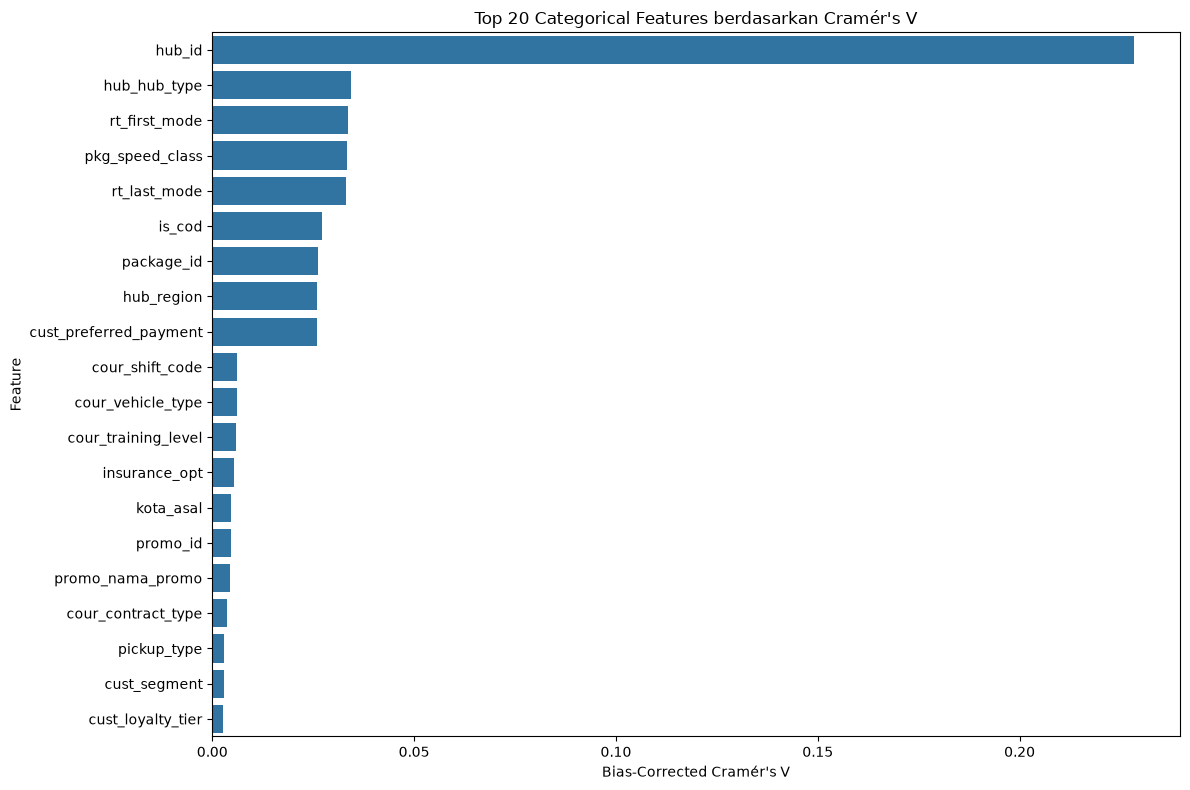

In [28]:
top_cramers = cramers_v_df.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_cramers,
    x="Cramers V",
    y="Feature"
)

plt.title("Top 20 Categorical Features berdasarkan Cramér's V")
plt.xlabel("Bias-Corrected Cramér's V")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 5.6 Analisis Mutual Information

Mutual Information digunakan untuk mengukur seberapa banyak informasi yang diberikan suatu fitur mengenai variabel target.

Berbeda dengan korelasi linear, Mutual Information dapat mengidentifikasi hubungan yang bersifat non-linear maupun non-monotonik.

Nilai Mutual Information yang lebih tinggi menunjukkan bahwa suatu fitur memberikan informasi lebih besar mengenai kategori target.

Analisis dilakukan terhadap fitur numerik dan kategorikal menggunakan representasi data yang sesuai dengan karakteristik masing-masing fitur.

Fitur numerik akan diproses sebagai variabel kontinu, sedangkan fitur kategorikal akan diubah menjadi kode kategori dan diperlakukan sebagai variabel diskrit.

Pengukuran dilakukan menggunakan sampel data agar komputasi lebih efisien.

Hasil Mutual Information digunakan sebagai pelengkap Eta-squared dan Cramér's V untuk mengevaluasi potensi informasi prediktif setiap fitur.

In [29]:
MI_MAX_CATEGORICAL_CARDINALITY = 700

mi_numeric_features = [
    feature
    for feature in eta_squared_df
    .head(30)["Feature"]
    .tolist()
    if str(analysis_frame.schema[feature]) != "Boolean"
]

mi_categorical_features = [
    feature
    for feature in categorical_features
    if categorical_cardinality[feature] <= MI_MAX_CATEGORICAL_CARDINALITY
]

mi_feature_columns = list(dict.fromkeys(
    mi_numeric_features + mi_categorical_features
))

mi_sample = (
    analysis_frame
    .select([TARGET] + mi_feature_columns)
    .sample(
        n=min(MI_SAMPLE_SIZE, analysis_frame.height),
        seed=SEED
    )
    .to_pandas()
)

print("Mutual Information sample size:", len(mi_sample))
print("Numerical features:", len(mi_numeric_features))
print("Categorical features:", len(mi_categorical_features))

Mutual Information sample size: 50000
Numerical features: 30
Categorical features: 34


In [30]:
mi_matrix_columns = []
mi_feature_names = []
mi_discrete_flags = []

for feature in mi_numeric_features:

    values = pd.to_numeric(
        mi_sample[feature],
        errors="coerce"
    ).replace(
        [np.inf, -np.inf],
        np.nan
    )

    if values.nunique(dropna=True) <= 1:
        continue

    median_value = values.median()

    if pd.isna(median_value):
        median_value = 0

    mi_matrix_columns.append(
        values.fillna(median_value).to_numpy(dtype=np.float64)
    )

    mi_feature_names.append(feature)
    mi_discrete_flags.append(False)

for feature in mi_categorical_features:

    values = (
        mi_sample[feature]
        .astype("string")
        .fillna("__MISSING__")
    )

    codes, unique_values = pd.factorize(values)

    if len(unique_values) <= 1:
        continue

    mi_matrix_columns.append(
        codes.astype(np.float64)
    )

    mi_feature_names.append(feature)
    mi_discrete_flags.append(True)

X_mi = np.column_stack(
    mi_matrix_columns
)

y_mi = pd.Categorical(
    mi_sample[TARGET],
    categories=TARGET_CLASSES
).codes

discrete_mask = np.asarray(
    mi_discrete_flags,
    dtype=bool
)

print("MI matrix shape:", X_mi.shape)
print("Target shape:", y_mi.shape)

MI matrix shape: (50000, 64)
Target shape: (50000,)


In [31]:
mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    discrete_features=discrete_mask,
    n_neighbors=3,
    random_state=SEED
)

mutual_information_df = pd.DataFrame({
    "Feature": mi_feature_names,
    "Mutual Information": mi_scores,
    "Feature Type": [
        "Categorical" if value else "Numerical"
        for value in mi_discrete_flags
    ]
}).sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

display(mutual_information_df)

,Feature,Mutual Information,Feature Type
0,cust_address_quality,0.181710,Numerical
1,hub_id,0.177347,Categorical
2,cust_complaint_index,0.172736,Numerical
3,hub_density_index,0.137603,Numerical
4,hub_capacity_index,0.137565,Numerical
...,...,...,...
59,cust_is_business,0.000049,Categorical
60,insurance_opt,0.000031,Categorical
61,cust_is_verified,0.000021,Categorical
62,pkg_handling_class,0.000012,Categorical


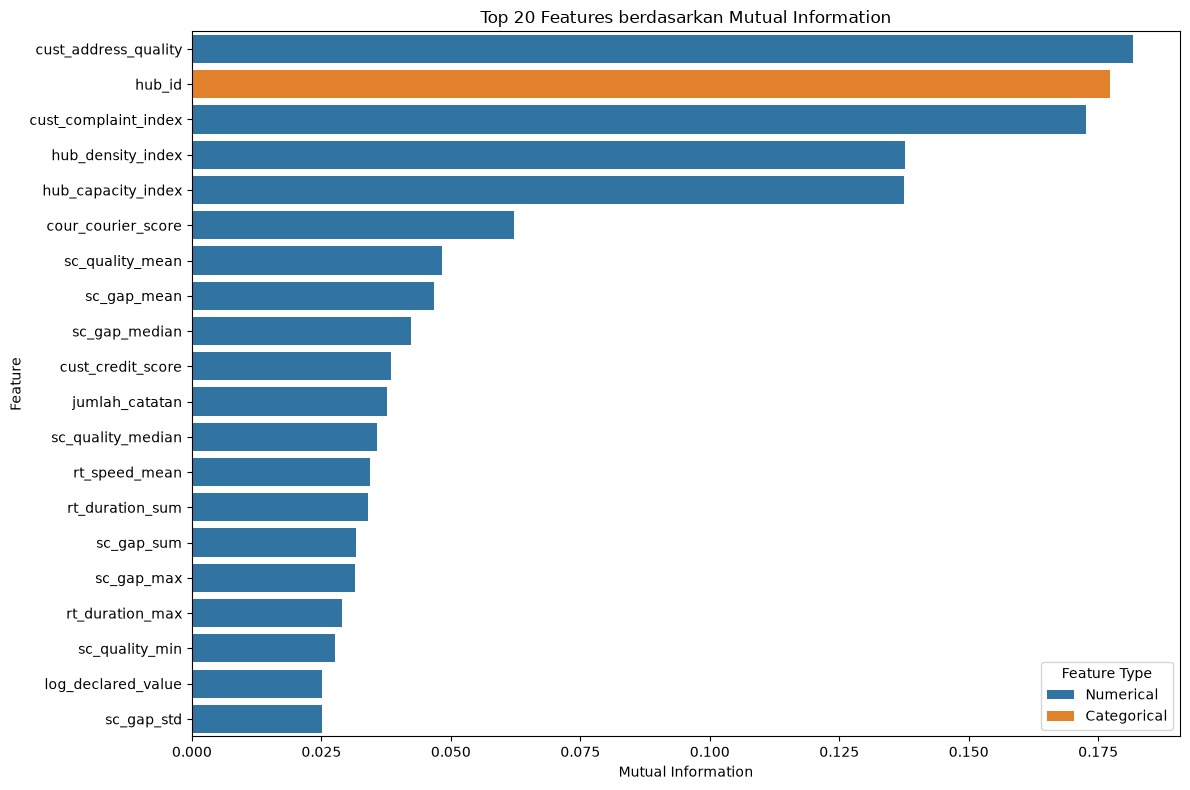

In [32]:
top_mi = mutual_information_df.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_mi,
    x="Mutual Information",
    y="Feature",
    hue="Feature Type"
)

plt.title("Top 20 Features berdasarkan Mutual Information")
plt.xlabel("Mutual Information")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 5.7 Analisis Interaksi Fitur Numerik

Analisis univariat hanya mengukur hubungan antara satu fitur dengan target secara individual.

Namun, karakteristik suatu shipment dapat dipengaruhi oleh kombinasi beberapa faktor.

Oleh karena itu, dilakukan analisis interaksi fitur untuk mengidentifikasi kemungkinan hubungan yang tidak terlihat ketika masing-masing fitur dianalisis secara terpisah.

Interaksi yang diuji mencakup:

1. Jarak pengiriman dengan tingkat kerapuhan paket.
2. Nilai barang dengan kepemilikan asuransi.
3. Kondisi alamat baru dengan jumlah catatan.
4. Beban operasional hub dengan durasi perjalanan.
5. Jarak pengiriman dengan kompleksitas segmen rute.

Fitur interaksi dibentuk melalui operasi matematis berdasarkan karakteristik masing-masing variabel.

Kekuatan asosiasi fitur interaksi terhadap target kemudian dibandingkan dengan asosiasi fitur penyusunnya menggunakan eta-squared.

Tujuannya adalah mengetahui apakah kombinasi beberapa variabel memberikan informasi tambahan mengenai status penanganan.

In [33]:
interaction_specs = {
    "x_distance_fragility": [
        "distance_km",
        "pkg_fragile_score"
    ],
    "x_value_insurance": [
        "log_declared_value",
        "insurance_opt"
    ],
    "x_address_notes": [
        "jumlah_catatan",
        "flag_alamat_baru"
    ],
    "x_hub_load_duration": [
        "r_hub_load",
        "rt_duration_sum"
    ],
    "x_distance_route_complexity": [
        "distance_km",
        "rt_count"
    ],
    "x_weight_fragility": [
        "weight_kg",
        "pkg_fragile_score"
    ]
}

interaction_expressions = [
    (
        pl.col("distance_km")
        * pl.col("pkg_fragile_score")
    ).alias("x_distance_fragility"),

    (
        pl.col("log_declared_value")
        * pl.col("insurance_opt").cast(pl.Float64, strict=False)
    ).alias("x_value_insurance"),

    (
        pl.col("jumlah_catatan")
        * pl.col("flag_alamat_baru")
    ).alias("x_address_notes"),

    (
        pl.col("r_hub_load")
        * pl.col("rt_duration_sum")
    ).alias("x_hub_load_duration"),

    (
        pl.col("distance_km")
        * pl.col("rt_count")
    ).alias("x_distance_route_complexity"),

    (
        pl.col("weight_kg")
        * pl.col("pkg_fragile_score")
    ).alias("x_weight_fragility")
]

analysis_frame = analysis_frame.with_columns(
    interaction_expressions
)

interaction_features = list(
    interaction_specs.keys()
)

print("Total interaction features:", len(interaction_features))

Total interaction features: 6


In [34]:
interaction_eta_df = calculate_eta_squared(
    analysis_frame,
    TARGET,
    interaction_features
)

eta_lookup = dict(
    zip(
        eta_squared_df["Feature"],
        eta_squared_df["Eta Squared"]
    )
)

interaction_results = []

for _, row in interaction_eta_df.iterrows():

    interaction = row["Feature"]

    parents = interaction_specs[interaction]

    parent_scores = [
        eta_lookup.get(parent, np.nan)
        for parent in parents
    ]

    strongest_parent = (
        np.nanmax(parent_scores)
        if np.isfinite(parent_scores).any()
        else np.nan
    )

    interaction_results.append({
        "Interaction": interaction,
        "Parent Features": " × ".join(parents),
        "Interaction Eta Squared": row["Eta Squared"],
        "Strongest Parent Eta Squared": strongest_parent,
        "Additional Association": (
            row["Eta Squared"] - strongest_parent
            if np.isfinite(strongest_parent)
            else np.nan
        )
    })

interaction_eta_comparison_df = pd.DataFrame(
    interaction_results
).sort_values(
    "Interaction Eta Squared",
    ascending=False
).reset_index(drop=True)

display(interaction_eta_comparison_df)

,Interaction,Parent Features,Interaction Eta Squared,Strongest Parent Eta Squared,Additional Association
0,x_distance_route_complexity,distance_km × rt_count,0.041106,0.034831,0.006275
1,x_address_notes,jumlah_catatan × flag_alamat_baru,0.023150,0.064267,-0.041117
2,x_hub_load_duration,r_hub_load × rt_duration_sum,0.022340,0.064702,-0.042362
3,x_distance_fragility,distance_km × pkg_fragile_score,0.022164,0.034831,-0.012666
4,x_value_insurance,log_declared_value × insurance_opt,0.000430,0.044066,-0.043636
5,x_weight_fragility,weight_kg × pkg_fragile_score,0.000397,0.002116,-0.001719


### 5.8 Analisis Interaksi Fitur Kategorikal

Analisis dilanjutkan dengan menguji kombinasi beberapa fitur kategorikal atau fitur numerik yang telah dikelompokkan ke dalam kategori.

Pendekatan ini digunakan untuk mengetahui apakah kombinasi dua karakteristik mempunyai hubungan yang lebih kuat dengan status penanganan dibandingkan masing-masing fitur secara individual.

Interaksi yang dieksplorasi meliputi:

1. Kategori jarak perjalanan dengan tingkat kerapuhan paket.
2. Kategori nilai barang dengan kepemilikan asuransi.
3. Jumlah catatan dengan status alamat baru.
4. Beban hub dengan kompleksitas durasi perjalanan.

Fitur numerik akan dibagi ke dalam kelompok menggunakan quantile binning atau batas kategori yang relevan secara bisnis.

Setelah itu, kombinasi kategori akan dibandingkan dengan target menggunakan Cramér's V.

Analisis distribusi target pada setiap kombinasi juga dilakukan untuk mengidentifikasi kelompok yang mempunyai konsentrasi kelas tertentu.

In [35]:
BIVARIATE_COLUMNS = [
    TARGET,
    "distance_km",
    "pkg_fragile_score",
    "declared_value",
    "insurance_opt",
    "jumlah_catatan",
    "flag_alamat_baru",
    "r_hub_load",
    "rt_duration_sum"
]

bivariate_sample = (
    analysis_frame
    .select(BIVARIATE_COLUMNS)
    .sample(
        n=min(100000, analysis_frame.height),
        seed=SEED
    )
    .to_pandas()
)

print("Bivariate sample size:", len(bivariate_sample))

Bivariate sample size: 100000


In [36]:
def quantile_bucket(series, q=4):

    values = pd.to_numeric(
        series,
        errors="coerce"
    )

    result = pd.qcut(
        values,
        q=q,
        duplicates="drop"
    )

    return (
        result.astype("string")
        .fillna("__MISSING__")
    )

bivariate_sample["distance_group"] = quantile_bucket(
    bivariate_sample["distance_km"],
    q=4
)

bivariate_sample["fragility_group"] = quantile_bucket(
    bivariate_sample["pkg_fragile_score"],
    q=3
)

bivariate_sample["value_group"] = quantile_bucket(
    bivariate_sample["declared_value"],
    q=4
)

bivariate_sample["hub_load_group"] = quantile_bucket(
    bivariate_sample["r_hub_load"],
    q=3
)

bivariate_sample["route_duration_group"] = quantile_bucket(
    bivariate_sample["rt_duration_sum"],
    q=3
)

bivariate_sample["notes_group"] = pd.cut(
    pd.to_numeric(
        bivariate_sample["jumlah_catatan"],
        errors="coerce"
    ),
    bins=[
        -np.inf,
        0,
        1,
        2,
        np.inf
    ],
    labels=[
        "0",
        "1",
        "2",
        "3+"
    ]
).astype("string").fillna("__MISSING__")

bivariate_sample["insurance_group"] = (
    bivariate_sample["insurance_opt"]
    .astype("string")
    .fillna("__MISSING__")
)

bivariate_sample["new_address_group"] = (
    bivariate_sample["flag_alamat_baru"]
    .astype("string")
    .fillna("__MISSING__")
)

In [37]:
categorical_interactions = {
    "Distance × Fragility": [
        "distance_group",
        "fragility_group"
    ],
    "Declared Value × Insurance": [
        "value_group",
        "insurance_group"
    ],
    "Address Notes × New Address": [
        "notes_group",
        "new_address_group"
    ],
    "Hub Load × Route Duration": [
        "hub_load_group",
        "route_duration_group"
    ]
}

bivariate_cramers_records = []
bivariate_profile_records = []

for interaction, columns in categorical_interactions.items():

    joint_feature = (
        bivariate_sample[columns[0]].astype(str)
        + " × "
        + bivariate_sample[columns[1]].astype(str)
    )

    score = calculate_cramers_v(
        joint_feature,
        bivariate_sample[TARGET]
    )

    bivariate_cramers_records.append({
        "Interaction": interaction,
        "Cramers V": score,
        "Number of Groups": joint_feature.nunique(),
        "Sample Size": len(bivariate_sample)
    })

    profile = pd.crosstab(
        joint_feature,
        bivariate_sample[TARGET],
        normalize="index"
    ) * 100

    profile = profile.reset_index()

    profile = profile.rename(
        columns={
            "row_0": "Interaction Group",
            profile.columns[0]: "Interaction Group"
        }
    )

    profile["Interaction"] = interaction

    bivariate_profile_records.append(profile)

bivariate_interaction_cramers_df = pd.DataFrame(
    bivariate_cramers_records
)

bivariate_interaction_profile_df = pd.concat(
    bivariate_profile_records,
    ignore_index=True
)

display(bivariate_interaction_cramers_df)

,Interaction,Cramers V,Number of Groups,Sample Size
0,Distance × Fragility,0.074676,12,100000
1,Declared Value × Insurance,0.077068,8,100000
2,Address Notes × New Address,0.120541,8,100000
3,Hub Load × Route Duration,0.101052,9,100000


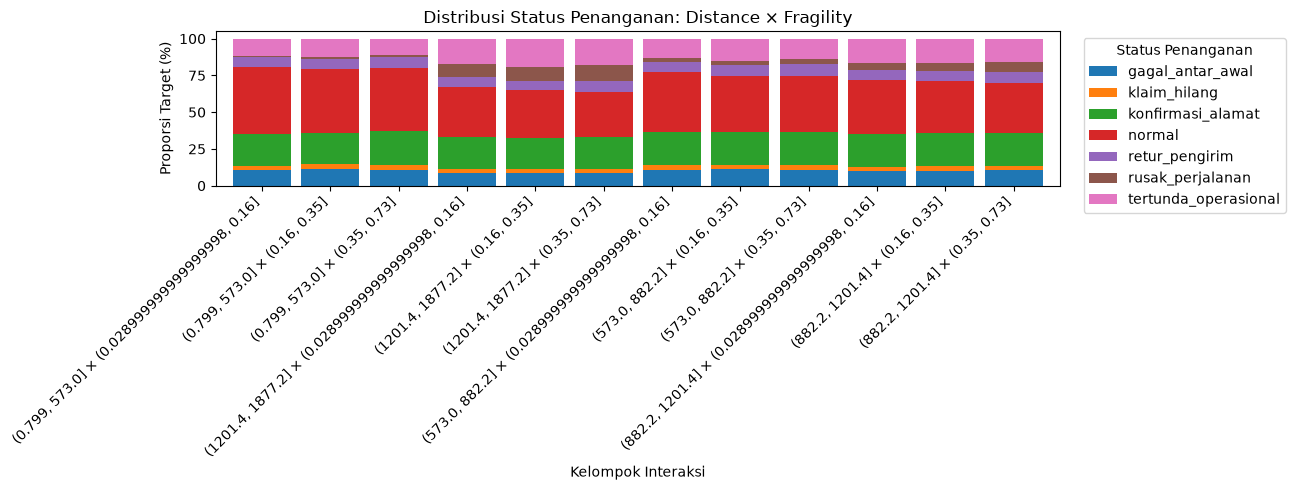

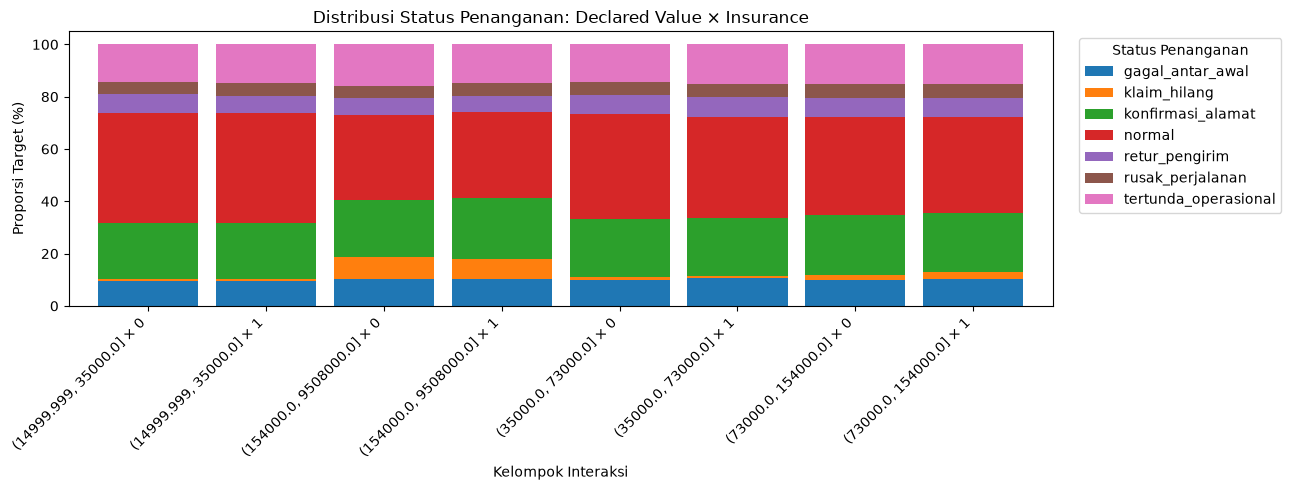

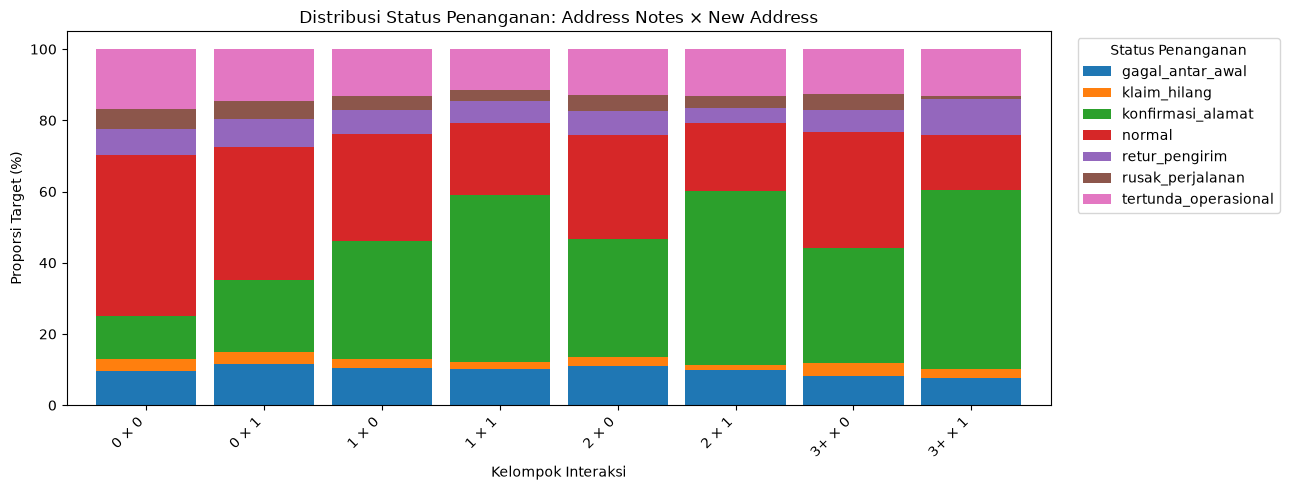

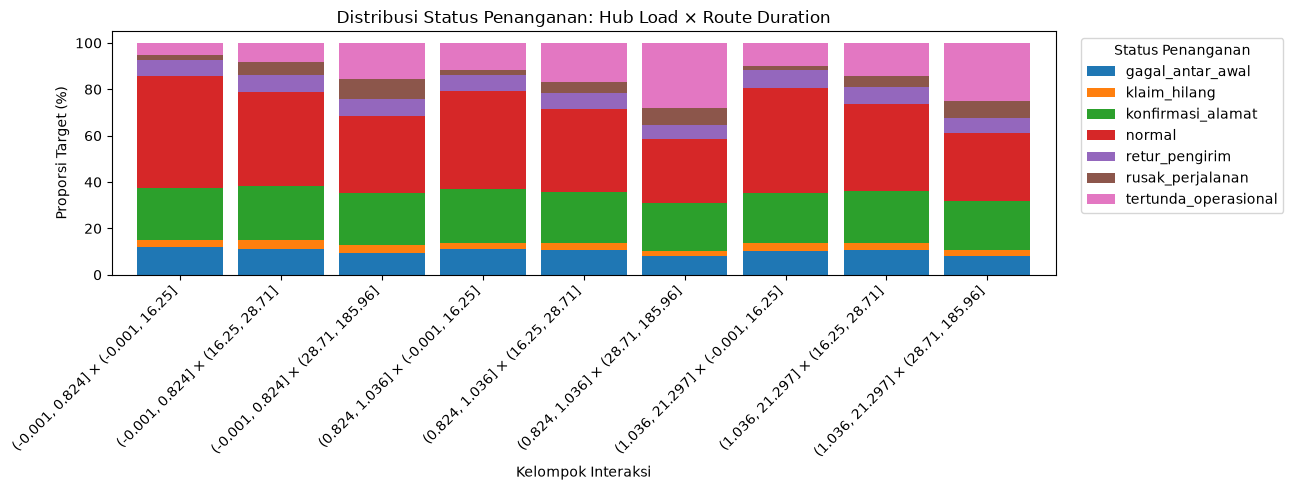

In [38]:
for interaction, columns in categorical_interactions.items():

    joint_feature = (
        bivariate_sample[columns[0]].astype(str)
        + " × "
        + bivariate_sample[columns[1]].astype(str)
    )

    profile = pd.crosstab(
        joint_feature,
        bivariate_sample[TARGET],
        normalize="index"
    ) * 100

    profile.plot(
        kind="bar",
        stacked=True,
        figsize=(13, 5),
        width=0.85
    )

    plt.title(
        f"Distribusi Status Penanganan: {interaction}"
    )

    plt.xlabel("Kelompok Interaksi")
    plt.ylabel("Proporsi Target (%)")
    plt.xticks(rotation=45, ha="right")
    plt.legend(
        title="Status Penanganan",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

### 5.9 Ranking Asosiasi Fitur

Tahap ini bertujuan untuk menggabungkan hasil pengukuran asosiasi dari beberapa metode statistik.

Tiga metode utama yang digunakan:

1. Eta-squared untuk fitur numerik.
2. Cramér's V untuk fitur kategorikal.
3. Mutual Information untuk fitur numerik dan kategorikal.

Setiap metode mempunyai karakteristik pengukuran yang berbeda sehingga nilai mentahnya tidak dapat dibandingkan secara langsung.

Untuk memperoleh ranking gabungan, setiap fitur akan diberikan peringkat berdasarkan masing-masing metode.

Hasil ranking digunakan untuk mengidentifikasi fitur yang secara konsisten menunjukkan asosiasi atau informasi yang tinggi terhadap target.

Standardized Mean Difference juga digunakan sebagai informasi tambahan untuk mengidentifikasi fitur yang memiliki karakteristik khusus pada kelas tertentu.

Ranking ini bersifat eksploratif dan akan digunakan sebagai dasar pemilihan fitur untuk eksperimen model.

In [39]:
eta_ranking = (
    eta_squared_df[
        ["Feature", "Eta Squared"]
    ]
    .copy()
)

eta_ranking["Eta Rank"] = eta_ranking[
    "Eta Squared"
].rank(
    ascending=False,
    method="min"
)

cramer_ranking = (
    cramers_v_df[
        ["Feature", "Cramers V"]
    ]
    .copy()
)

cramer_ranking["Cramers Rank"] = cramer_ranking[
    "Cramers V"
].rank(
    ascending=False,
    method="min"
)

mi_ranking = (
    mutual_information_df[
        ["Feature", "Mutual Information"]
    ]
    .copy()
)

mi_ranking["MI Rank"] = mi_ranking[
    "Mutual Information"
].rank(
    ascending=False,
    method="min"
)

smd_ranking = (
    classwise_smd_df
    .groupby("Feature", as_index=False)
    .agg(
        Max_Absolute_SMD=("Absolute SMD", "max")
    )
)

association_ranking_df = (
    eta_ranking
    .merge(
        cramer_ranking,
        on="Feature",
        how="outer"
    )
    .merge(
        mi_ranking,
        on="Feature",
        how="outer"
    )
    .merge(
        smd_ranking,
        on="Feature",
        how="left"
    )
)

rank_columns = [
    "Eta Rank",
    "Cramers Rank",
    "MI Rank"
]

association_ranking_df["Average Rank"] = (
    association_ranking_df[rank_columns]
    .mean(axis=1)
)

association_ranking_df = association_ranking_df.sort_values(
    "Average Rank",
    ascending=True
).reset_index(drop=True)

display(association_ranking_df.head(30))

,Feature,Eta Squared,Eta Rank,Cramers V,Cramers Rank,Mutual Information,MI Rank,Max_Absolute_SMD,Average Rank
0,cust_address_quality,0.307411,1.0,NaN,NaN,0.181710,1.0,1.469278,1.0
1,hub_id,NaN,NaN,0.228318,1.0,0.177347,2.0,NaN,1.5
2,cust_complaint_index,0.296791,2.0,NaN,NaN,0.172736,3.0,1.246359,2.5
3,hub_density_index,0.128459,3.0,NaN,NaN,0.137603,4.0,1.045958,3.5
4,cour_courier_score,0.119699,4.0,NaN,NaN,0.062204,6.0,0.849371,5.0
5,hub_capacity_index,0.110993,5.0,NaN,NaN,0.137565,5.0,0.954150,5.0
6,sc_gap_mean,0.099137,6.0,NaN,NaN,0.046757,8.0,0.906937,7.0
7,sc_quality_mean,0.094962,7.0,NaN,NaN,0.048378,7.0,1.041847,7.0
8,sc_gap_median,0.079214,8.0,NaN,NaN,0.042385,9.0,0.802468,8.5
9,sc_quality_median,0.075677,9.0,NaN,NaN,0.035789,12.0,0.931048,10.5


In [40]:
ranking_comparison_df = (
    association_ranking_df
    .head(20)
    [
        [
            "Feature",
            "Eta Rank",
            "Cramers Rank",
            "MI Rank",
            "Average Rank"
        ]
    ]
)

display(ranking_comparison_df)

,Feature,Eta Rank,Cramers Rank,MI Rank,Average Rank
0,cust_address_quality,1.0,NaN,1.0,1.0
1,hub_id,NaN,1.0,2.0,1.5
2,cust_complaint_index,2.0,NaN,3.0,2.5
3,hub_density_index,3.0,NaN,4.0,3.5
4,cour_courier_score,4.0,NaN,6.0,5.0
5,hub_capacity_index,5.0,NaN,5.0,5.0
6,sc_gap_mean,6.0,NaN,8.0,7.0
7,sc_quality_mean,7.0,NaN,7.0,7.0
8,sc_gap_median,8.0,NaN,9.0,8.5
9,sc_quality_median,9.0,NaN,12.0,10.5


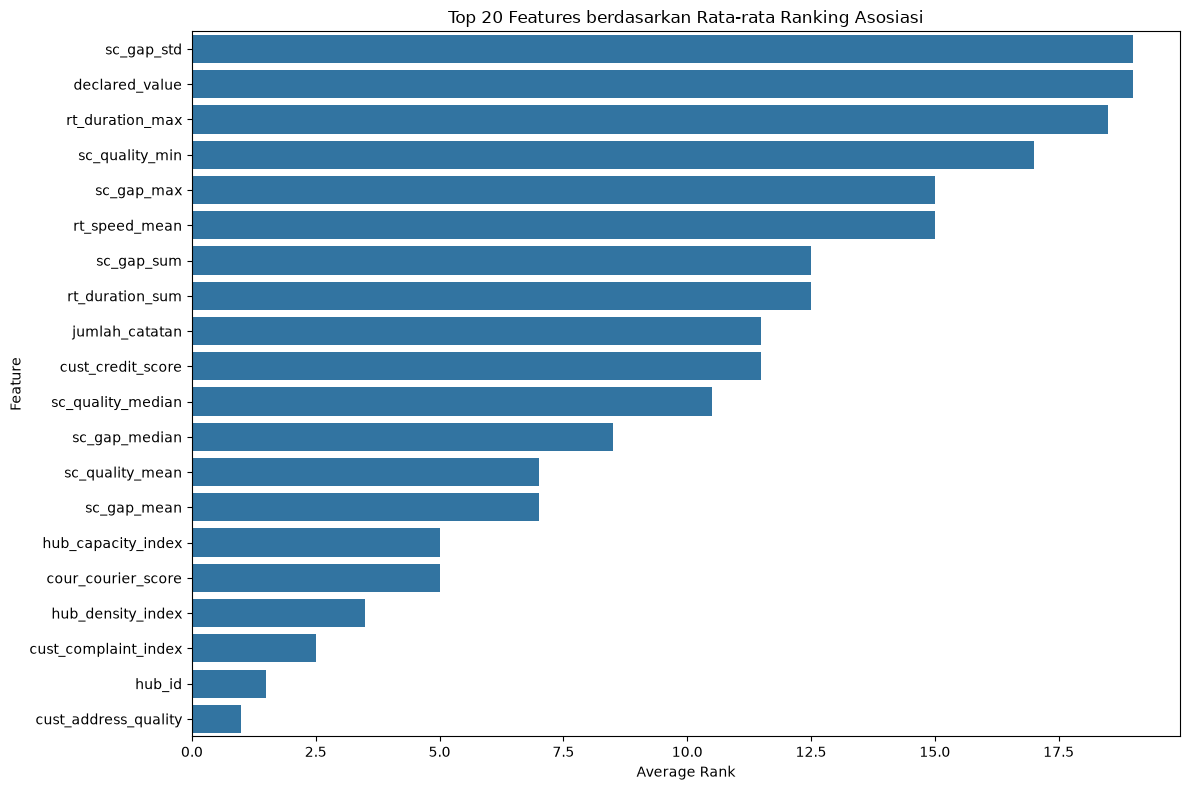

In [41]:
ranking_plot = (
    association_ranking_df
    .dropna(subset=["Average Rank"])
    .head(20)
    .sort_values("Average Rank", ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=ranking_plot,
    x="Average Rank",
    y="Feature"
)

plt.title("Top 20 Features berdasarkan Rata-rata Ranking Asosiasi")
plt.xlabel("Average Rank")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 5.10 Kesimpulan Analisis Univariate dan Bivariate

Tahap ini merangkum hasil pengukuran hubungan antara fitur dan variabel target.

Kesimpulan disusun berdasarkan:

1. Ranking asosiasi fitur numerik menggunakan eta-squared.
2. Perbedaan distribusi fitur pada setiap kelas.
3. Standardized Mean Difference untuk analisis one-versus-rest.
4. Ranking asosiasi fitur kategorikal menggunakan Cramér's V.
5. Ranking informasi prediktif menggunakan Mutual Information.
6. Hasil pengujian kombinasi fitur numerik dan kategorikal.

Fitur yang menunjukkan asosiasi tinggi akan diprioritaskan untuk eksperimen feature engineering.

Namun, asosiasi statistik tidak secara otomatis menunjukkan bahwa suatu fitur dapat meningkatkan performa klasifikasi.

Setiap kandidat fitur tetap perlu diuji menggunakan validasi silang dan feature ablation pada tahap modeling.

Hasil analisis ini juga akan digunakan untuk mengidentifikasi kemungkinan redundansi fitur, hubungan non-linear, serta potensi informasi yang dapat menyebabkan target leakage.

In [42]:
top_eta_features = (
    eta_squared_df.head(10)["Feature"].tolist()
)

top_cramer_features = (
    cramers_v_df.head(10)["Feature"].tolist()
)

top_mi_features = (
    mutual_information_df.head(10)["Feature"].tolist()
)

top_interaction_features = (
    interaction_eta_comparison_df
    .head(5)["Interaction"]
    .tolist()
)

top_class_specific_features = (
    classwise_smd_df
    .sort_values(
        "Absolute SMD",
        ascending=False
    )
    .groupby("Class")
    .head(3)
)

print("TOP NUMERICAL FEATURES")
display(eta_squared_df.head(10))

print("TOP CATEGORICAL FEATURES")
display(cramers_v_df.head(10))

print("TOP MUTUAL INFORMATION FEATURES")
display(mutual_information_df.head(10))

print("TOP CLASS-SPECIFIC FEATURES")
display(top_class_specific_features)

print("TOP NUMERICAL INTERACTIONS")
display(interaction_eta_comparison_df.head(5))

print("CATEGORICAL INTERACTION RESULTS")
display(bivariate_interaction_cramers_df)

TOP NUMERICAL FEATURES


,Feature,Eta Squared,Grand Mean,Valid Observations
0,cust_address_quality,0.307411,3.175691,1243617
1,cust_complaint_index,0.296791,0.241407,1243617
2,hub_density_index,0.128459,0.498544,1243617
3,cour_courier_score,0.119699,3.575678,1230239
4,hub_capacity_index,0.110993,0.538940,1243617
5,sc_gap_mean,0.099137,8.412638,1243617
6,sc_quality_mean,0.094962,3.636019,1243617
7,sc_gap_median,0.079214,7.048513,1243617
8,sc_quality_median,0.075677,3.686720,1243617
9,sc_gap_sum,0.066563,46.266478,1243617


TOP CATEGORICAL FEATURES


,Feature,Cramers V,Cardinality,Sample Size
0,hub_id,0.228318,654,150000
1,hub_hub_type,0.034247,3,150000
2,rt_first_mode,0.033611,4,150000
3,pkg_speed_class,0.033338,3,150000
4,rt_last_mode,0.033008,4,150000
5,is_cod,0.027097,2,150000
6,package_id,0.026079,62,150000
7,hub_region,0.025909,7,150000
8,cust_preferred_payment,0.025908,4,150000
9,cour_shift_code,0.006027,3,150000


TOP MUTUAL INFORMATION FEATURES


,Feature,Mutual Information,Feature Type
0,cust_address_quality,0.181710,Numerical
1,hub_id,0.177347,Categorical
2,cust_complaint_index,0.172736,Numerical
3,hub_density_index,0.137603,Numerical
4,hub_capacity_index,0.137565,Numerical
5,cour_courier_score,0.062204,Numerical
6,sc_quality_mean,0.048378,Numerical
7,sc_gap_mean,0.046757,Numerical
8,sc_gap_median,0.042385,Numerical
9,cust_credit_score,0.038356,Numerical


... (2 outputs left out)

TOP NUMERICAL INTERACTIONS


,Interaction,Parent Features,Interaction Eta Squared,Strongest Parent Eta Squared,Additional Association
0,x_distance_route_complexity,distance_km × rt_count,0.041106,0.034831,0.006275
1,x_address_notes,jumlah_catatan × flag_alamat_baru,0.023150,0.064267,-0.041117
2,x_hub_load_duration,r_hub_load × rt_duration_sum,0.022340,0.064702,-0.042362
3,x_distance_fragility,distance_km × pkg_fragile_score,0.022164,0.034831,-0.012666
4,x_value_insurance,log_declared_value × insurance_opt,0.000430,0.044066,-0.043636


CATEGORICAL INTERACTION RESULTS


,Interaction,Cramers V,Number of Groups,Sample Size
0,Distance × Fragility,0.074676,12,100000
1,Declared Value × Insurance,0.077068,8,100000
2,Address Notes × New Address,0.120541,8,100000
3,Hub Load × Route Duration,0.101052,9,100000


In [43]:
section05_outputs = {
    "eta_squared.csv": eta_squared_df,
    "numeric_class_distribution.csv": numeric_class_distribution_df,
    "classwise_smd.csv": classwise_smd_df,
    "cramers_v.csv": cramers_v_df,
    "mutual_information.csv": mutual_information_df,
    "interaction_eta_comparison.csv": interaction_eta_comparison_df,
    "bivariate_interaction_cramers.csv": bivariate_interaction_cramers_df,
    "bivariate_interaction_profile.csv": bivariate_interaction_profile_df,
    "feature_association_ranking.csv": association_ranking_df,
    "feature_ranking_comparison.csv": ranking_comparison_df
}

for filename, dataframe in section05_outputs.items():

    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("Section 05 completed.")
print("Total output files:", len(section05_outputs))
print("Output directory:", OUTPUT_DIR.resolve())

Section 05 completed.
Total output files: 10
Output directory: C:\Users\ASUS\.vscode\arkavidia\eda_outputs


## 5.11 Interpretasi Hasil dan Keputusan Analitis

Hasil analisis univariat dan bivariat akan digunakan untuk menentukan kandidat fitur yang memiliki potensi prediktif terhadap status penanganan.

Interpretasi dilakukan dengan mempertimbangkan beberapa aspek:

1. Kekuatan asosiasi statistik.
2. Konsistensi hubungan antarkelas.
3. Kemampuan membedakan kelas minoritas.
4. Informasi tambahan dari interaksi fitur.
5. Potensi redundansi antarvariabel.
6. Ketersediaan fitur pada saat prediksi.
7. Risiko target leakage.

Fitur tidak akan dipilih hanya berdasarkan nilai asosiasi tertinggi.

Keputusan akhir mengenai penggunaan fitur akan dilakukan melalui eksperimen feature ablation dan evaluasi cross-validation menggunakan Macro F1-score.

Hasil analisis juga akan menjadi dasar untuk menyusun strategi preprocessing, feature selection, dan model development.

In [44]:
method_summary = pd.DataFrame([
    {
        "Method": "Eta-squared",
        "Total Features": len(eta_squared_df),
        "Top Feature": (
            eta_squared_df.iloc[0]["Feature"]
            if not eta_squared_df.empty else None
        ),
        "Top Score": (
            eta_squared_df.iloc[0]["Eta Squared"]
            if not eta_squared_df.empty else np.nan
        )
    },
    {
        "Method": "Cramer's V",
        "Total Features": len(cramers_v_df),
        "Top Feature": (
            cramers_v_df.iloc[0]["Feature"]
            if not cramers_v_df.empty else None
        ),
        "Top Score": (
            cramers_v_df.iloc[0]["Cramers V"]
            if not cramers_v_df.empty else np.nan
        )
    },
    {
        "Method": "Mutual Information",
        "Total Features": len(mutual_information_df),
        "Top Feature": (
            mutual_information_df.iloc[0]["Feature"]
            if not mutual_information_df.empty else None
        ),
        "Top Score": (
            mutual_information_df.iloc[0]["Mutual Information"]
            if not mutual_information_df.empty else np.nan
        )
    }
])

display(method_summary)

,Method,Total Features,Top Feature,Top Score
0,Eta-squared,127,cust_address_quality,0.307411
1,Cramer's V,34,hub_id,0.228318
2,Mutual Information,64,cust_address_quality,0.181710


In [45]:
section05_outputs = {
    "eta_squared.csv": eta_squared_df,
    "numeric_class_distribution.csv": numeric_class_distribution_df,
    "classwise_smd.csv": classwise_smd_df,
    "cramers_v.csv": cramers_v_df,
    "mutual_information.csv": mutual_information_df,
    "interaction_eta_comparison.csv": interaction_eta_comparison_df,
    "bivariate_interaction_cramers.csv": bivariate_interaction_cramers_df,
    "bivariate_interaction_profile.csv": bivariate_interaction_profile_df,
    "feature_association_ranking.csv": association_ranking_df,
    "feature_ranking_comparison.csv": ranking_comparison_df,
    "method_summary.csv": method_summary
}

for filename, dataframe in section05_outputs.items():

    dataframe.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("Section 05 completed.")
print("Total output files:", len(section05_outputs))
print("Output directory:", OUTPUT_DIR.resolve())

Section 05 completed.
Total output files: 11
Output directory: C:\Users\ASUS\.vscode\arkavidia\eda_outputs
